1. Воспользуемся данными с соревнования Bank Marketing, где целевая переменная –  
подпишется клиент на срочный депозит или нет. 
2.  Закодируйте категориальные переменные. 
    a. Для month, day_of_week, education необходимо учесть порядок (можно, но 
    необязательно, воспользоваться функцией reorder_categories; 
    b. Для job сделайте One-Hot Encoding; 
    c. Для всех остальных категориальных колонок – Label Encoding; 
    d. Не забудьте представить целевую переменную в виде 1 и 0. 

In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bank-additional-full.csv", sep=";")   

print(df.head())
print(df.shape)

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

In [ ]:
# копия
data = df.copy()

# для классификации цель
data["y"] = data["y"].map({
    "yes": 1,
    "no": 0
})

# ordinal признаки

# month
month_order = [
    "mar","apr","may","jun","jul","aug",
    "sep","oct","nov","dec"
]

data["month"] = pd.Categorical(
    data["month"],
    categories=month_order,
    ordered=True
).codes

# day_of_week
day_order = ["mon","tue","wed","thu","fri"]

data["day_of_week"] = pd.Categorical(
    data["day_of_week"],
    categories=day_order,
    ordered=True
).codes

# education
edu_order = [
    "illiterate",
    "basic.4y",
    "basic.6y",
    "basic.9y",
    "high.school",
    "professional.course",
    "university.degree",
    "unknown"
]

data["education"] = pd.Categorical(
    data["education"],
    categories=edu_order,
    ordered=True
).codes

#  One-Hot
data = pd.get_dummies(data, columns=["job"], drop_first=True)

# Label Encoding остальных категориальных

cat_cols = data.select_dtypes(include="object").columns.tolist()
cat_cols.remove("y") if "y" in cat_cols else None

le = LabelEncoder()

for col in cat_cols:
    data[col] = le.fit_transform(data[col])

C:\Users\Vlad2\AppData\Local\Temp\ipykernel_25008\2216860272.py:59: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = data.select_dtypes(include="object").columns.tolist()


3. Нормализуйте признаки с помощью MinMaxScaler. 

In [ ]:
# Train/Test

X = data.drop(columns=["y"])
y = data["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Нормализация

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

4. Обучите логистическую регрессию. Выведите classification report, посчитайте ROC
AUC. Что можно сказать о качестве модели? 

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.92      0.98      0.95     10965
           1       0.69      0.37      0.48      1392

    accuracy                           0.91     12357
   macro avg       0.81      0.67      0.71     12357
weighted avg       0.90      0.91      0.90     12357

ROC-AUC: 0.9294


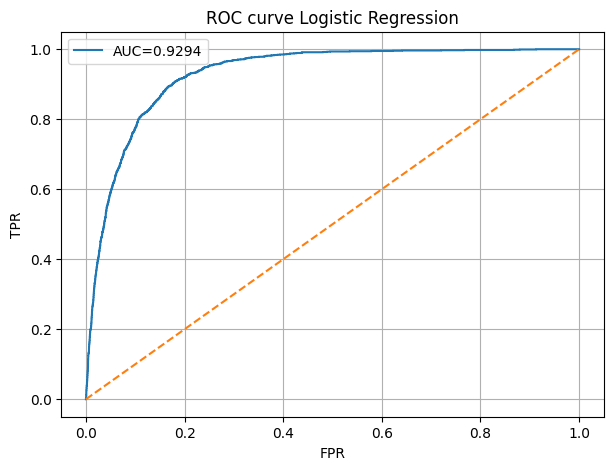

In [ ]:
logreg = LogisticRegression(
    max_iter=5000,
    random_state=42
)

logreg.fit(X_train_scaled, y_train)

pred = logreg.predict(X_test_scaled)
proba = logreg.predict_proba(X_test_scaled)[:,1]

print("=== Logistic Regression ===")
print(classification_report(y_test, pred))

roc = roc_auc_score(y_test, proba)
print("ROC-AUC:", round(roc,4))

# ROC curve

fpr, tpr, _ = roc_curve(y_test, proba)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"AUC={roc:.4f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC curve Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

Модель логистической регрессии показывает высокое общее качество классификации. Точность (accuracy) составляет 0.91, однако этот показатель не полностью отражает реальную эффективность из-за дисбаланса классов.

Для большинства клиентов, которые не подписались на депозит (класс 0), модель работает очень хорошо:

precision = 0.92
recall = 0.98

Это означает, что модель почти всегда корректно определяет клиентов, которые не оформят депозит.

Однако для целевого класса (класс 1 — подписка на депозит) качество заметно ниже:

precision = 0.69
recall = 0.37
f1-score = 0.48

Это говорит о том, что модель достаточно часто пропускает потенциальных клиентов (низкий recall) и обнаруживает лишь часть реальных подписок

Значение ROC-AUC = 0.9294 говорит о том, что модель очень хорошо разделяет классы по вероятностям, даже несмотря на слабый recall по классу 1.

precision (точность)
Если модель сказала, что это класс 1 - насколько часто она права?

recall (полнота)
А сколько всех реальных клиентов класса модель нашла?

f1-score - это баланс между precision и recall
f1 = (2 * precision * recall) / (precision + recall)

если precision высокий, но recall низкий -> f1 убывает
если оба хорошие -> f1 высокий

support - просто количество объектов в классе (данные несбалансированы (очень мало 1))

accuracy (точность модели) - доля всех правильных ответов

accuracy может быть обманчивой при дисбалансе классов

macro avg
среднее по классам без учёта их размера
класс 0 и 1 считаются одинаково важными
weighted avg
среднее с учётом количества объектов
класс 0 влияет сильнее (его больше)

ROC-AUC отвечает на вопрос:
насколько хорошо модель различает классы (0 и 1), независимо от порога?

ROC curve (ROC-кривая)
Это график:
X = False Positive Rate (ложные тревоги)
Y = True Positive Rate (нахожу правильные 1)

5. Подберите параметры penalty и C с помощью GridSearch. Получилось ли увеличить 
ROC-AUC из предыдущего пункта?

In [ ]:
# GridSearch LogisticRegression

params = {
    "penalty": ["l1", "l2"],
    "C": [0.01, 0.1, 1, 5, 10],
    "solver": ["liblinear"]
}

grid_log = GridSearchCV(
    LogisticRegression(max_iter=5000),
    param_grid=params,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

grid_log.fit(X_train_scaled, y_train)

print("Best params:", grid_log.best_params_)
print("Best CV ROC-AUC:", round(grid_log.best_score_,4))

best_log = grid_log.best_estimator_

proba = best_log.predict_proba(X_test_scaled)[:,1]
roc = roc_auc_score(y_test, proba)

print("Test ROC-AUC after tuning:", round(roc,4))


c:\Users\Vlad2\OneDrive\Documents\GitHub\machine-learning\taxi_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Vlad2\OneDrive\Documents\GitHub\machine-learning\taxi_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best params: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV ROC-AUC: 0.9269
Test ROC-AUC after tuning: 0.9311


После подбора гиперпараметров:
 C = 10, penalty = l1
Best CV ROC-AUC = 0.9269
Test ROC-AUC = 0.9311

Подбор параметров привёл к незначительному улучшению ROC-AUC на тестовой выборке (с 0.9294 до 0.9311)
вывод:
улучшение есть, но очень небольшое
модель логистической регрессии уже близка к своему оптимальному качеству для этих данных
сильного выигрыша от настройки регуляризации не наблюдается

6. Подберите параметры n_estimators и max_features для модели RandomForest с 
помощью GridSearch. Получилось ли увеличить ROC-AUC из предыдущего пункта?

In [ ]:
# RandomForest GridSearch

rf = RandomForestClassifier(random_state=42)

params_rf = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", "log2", None]
}

grid_rf = GridSearchCV(
    rf,
    param_grid=params_rf,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Best RF params:", grid_rf.best_params_)
print("Best RF CV ROC-AUC:", round(grid_rf.best_score_,4))

best_rf = grid_rf.best_estimator_

proba_rf = best_rf.predict_proba(X_test)[:,1]
roc_rf = roc_auc_score(y_test, proba_rf)

print("Random Forest Test ROC-AUC:", round(roc_rf,4))


Best RF params: {'max_features': 'sqrt', 'n_estimators': 300}
Best RF CV ROC-AUC: 0.9434
Random Forest Test ROC-AUC: 0.9453


Для модели случайного леса были подобраны параметры:

n_estimators = 300
max_features = sqrt
по итогу:
Best CV ROC-AUC = 0.9434
Test ROC-AUC = 0.9453

Модель Random Forest показывает более высокое качество по сравнению с логистической регрессией.

ROC-AUC увеличился с:
~0.93 (Logistic Regression)
до
0.9453 (Random Forest)

Random Forest после подбора параметров:
показывает лучшее разделение классов
имеет более высокий ROC-AUC
превосходит логистическую регрессию как до, так и после GridSearch